# **Getaround - Delay Dataset EDA**
---
Author :
Christophe NORET

In [1]:
# Import necessary libraries
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Exploratory Data Analysis

## Loading dataset

In [2]:
# Load the dataset: from the repo when run locally, from GitHub on Colab
from pathlib import Path

DATA_DIR = Path("../data")
DATA_URL = "https://raw.githubusercontent.com/cnoret/getaround-pricing/main/data/"
data_source = str(DATA_DIR) + "/" if DATA_DIR.exists() else DATA_URL
df = pd.read_excel(data_source + "get_around_delay_analysis_base.xlsx", sheet_name="rentals_data")

In [3]:
# Display the first few rows for a quick preview
print("Preview of the first few rows:")
df.head()

Preview of the first few rows:


,rental_id,car_id,checkin_type,state,delay_at_checkout_in_minutes,previous_ended_rental_id,time_delta_with_previous_rental_in_minutes
0,505000,363965,mobile,canceled,NaN,NaN,NaN
1,507750,269550,mobile,ended,-81.0,NaN,NaN
2,508131,359049,connect,ended,70.0,NaN,NaN
3,508865,299063,connect,canceled,NaN,NaN,NaN
4,511440,313932,mobile,ended,NaN,NaN,NaN


## Business question: how long should the minimum gap be?

A **conflict** is a rental whose previous rental, on the same car, came back later than the planned gap. A buffer of *N* minutes blocks every booking planned less than *N* minutes after the previous one: it removes the conflicts on those bookings, and the bookings themselves.

This section works on the **raw export**: missing delays stay missing and long delays are kept, so no conflict is hidden by cleaning. The same logic runs in the dashboard (`dashboard/delay.py`).

In [4]:
DELAY = "delay_at_checkout_in_minutes"
GAP = "time_delta_with_previous_rental_in_minutes"
PREVIOUS = "previous_ended_rental_id"
previous_delay = df.set_index("rental_id")[DELAY]


def buffer_impact(rentals, threshold, checkin_type=None, state="ended"):
    """Conflicts avoided and rentals blocked by a minimum gap of `threshold` minutes."""
    scoped = rentals[rentals["state"] == state]
    if checkin_type is not None:
        scoped = scoped[scoped["checkin_type"] == checkin_type]
    chained = scoped.dropna(subset=[PREVIOUS, GAP])
    chained = chained.assign(previous_delay=chained[PREVIOUS].map(previous_delay))
    known = chained.dropna(subset=["previous_delay"])
    conflicts = known[known["previous_delay"] > known[GAP]]
    return {
        "buffer (min)": threshold,
        "conflicts": len(conflicts),
        "conflict rate (%)": round(100 * len(conflicts) / len(known), 1),
        "conflicts avoided (%)": round(100 * (conflicts[GAP] < threshold).mean(), 1),
        "rentals blocked (%)": round(100 * (chained[GAP] < threshold).sum() / len(scoped), 1),
    }


scenarios = {"All cars": None, "Connect only": "connect"}
tradeoff = pd.concat(
    {
        name: pd.DataFrame([buffer_impact(df, t, scope) for t in range(0, 361, 30)])
        for name, scope in scenarios.items()
    },
    names=["scope", None],
).reset_index(level=0)
tradeoff[tradeoff["buffer (min)"].isin([30, 60, 90, 120])]

,scope,buffer (min),conflicts,conflict rate (%),conflicts avoided (%),rentals blocked (%)
1,All cars,30,181,11.9,54.7,1.4
2,All cars,60,181,11.9,70.2,2.0
3,All cars,90,181,11.9,81.8,2.9
4,All cars,120,181,11.9,85.6,3.3
1,Connect only,30,50,7.5,60.0,3.1
2,Connect only,60,50,7.5,76.0,4.4
3,Connect only,90,50,7.5,88.0,6.3
4,Connect only,120,50,7.5,92.0,7.2


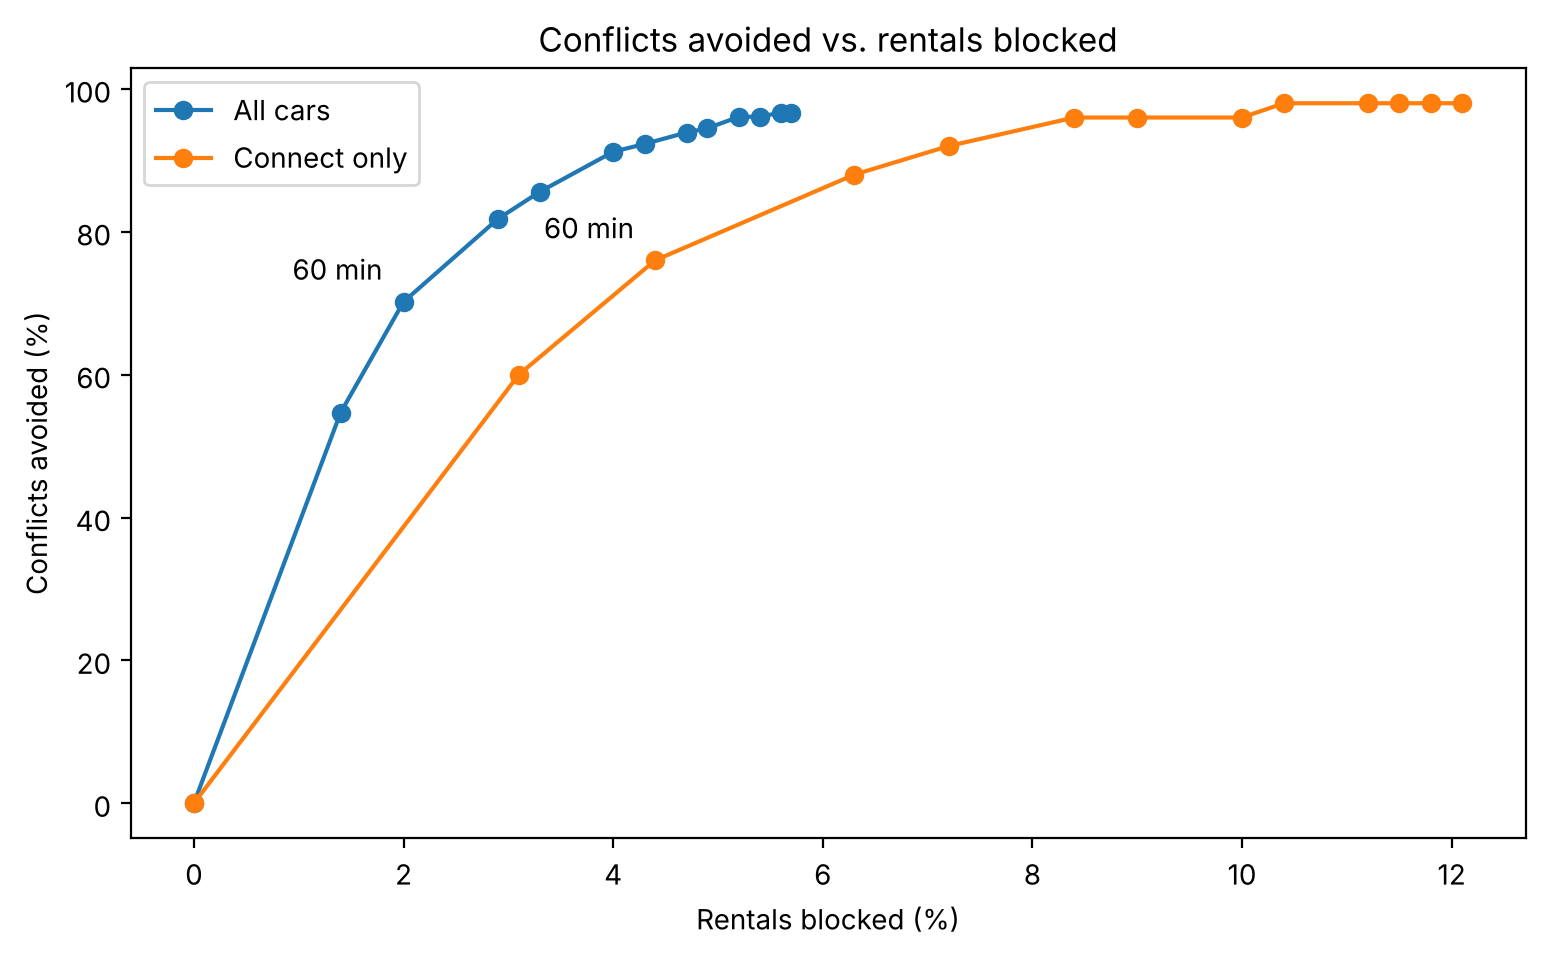

In [5]:
# Trade-off curve: each point is a buffer length, every 30 minutes
fig, ax = plt.subplots(figsize=(9, 5))
for name, curve in tradeoff.groupby("scope"):
    ax.plot(curve["rentals blocked (%)"], curve["conflicts avoided (%)"], marker="o", label=name)
    point = curve[curve["buffer (min)"] == 60].iloc[0]
    ax.annotate("60 min", (point["rentals blocked (%)"], point["conflicts avoided (%)"]),
                textcoords="offset points", xytext=(-40, 8))
ax.set_xlabel("Rentals blocked (%)")
ax.set_ylabel("Conflicts avoided (%)")
ax.set_title("Conflicts avoided vs. rentals blocked")
ax.legend()
plt.show()

### Canceled bookings after a late return

Canceled rentals also carry a previous rental and a planned gap. When the previous renter ran over that gap, the cancellation was likely caused by the late return. The reason for a cancellation is not recorded, so these cases are kept apart from the headline figures.

In [6]:
# Same 60-minute buffer, on ended and on canceled rentals
pd.DataFrame([{"rentals": state, **buffer_impact(df, 60, state=state)} for state in ["ended", "canceled"]])

,rentals,buffer (min),conflicts,conflict rate (%),conflicts avoided (%),rentals blocked (%)
0,ended,60,181,11.9,70.2,2.0
1,canceled,60,37,18.0,51.4,1.3


**Reading:** with a 60-minute buffer, 70% of conflicts are avoided for 2.0% of ended rentals blocked. The curve rises steeply up to about an hour, then each extra 30 minutes avoids fewer conflicts for more blocked rentals. Connect cars chain rentals more often, so the same buffer blocks about twice the share of their rentals (4.4%).

Among canceled bookings that follow another rental with a known delay, 18% were hit by a late return, against 12% for ended rentals: late returns very likely drive part of the cancellations. A 60-minute buffer would have prevented 19 of these 37 cancellations.

## Data cleaning for the charts below

The rest of the notebook is descriptive EDA. It fills missing delays with 0 and caps outliers with the IQR rule so the distributions stay readable. **These cleaned values are not used for the buffer figures above**, which must keep long delays and leave unknown delays out.

## Dataset characteristics

In [7]:
# Display information about the columns and data types
print("\nInformation on columns and types:")
print(df.info())


Information on columns and types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21310 entries, 0 to 21309
Data columns (total 7 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   rental_id                                   21310 non-null  int64  
 1   car_id                                      21310 non-null  int64  
 2   checkin_type                                21310 non-null  object 
 3   state                                       21310 non-null  object 
 4   delay_at_checkout_in_minutes                16346 non-null  float64
 5   previous_ended_rental_id                    1841 non-null   float64
 6   time_delta_with_previous_rental_in_minutes  1841 non-null   float64
dtypes: float64(3), int64(2), object(2)
memory usage: 1.1+ MB
None


In [8]:
# Descriptive statistics
print("\nDescriptive statistics for numeric columns:")
display(df.describe())


Descriptive statistics for numeric columns:


,rental_id,car_id,delay_at_checkout_in_minutes,previous_ended_rental_id,time_delta_with_previous_rental_in_minutes
count,21310.000000,21310.000000,16346.000000,1841.000000,1841.000000
mean,549712.880338,350030.603426,59.701517,550127.411733,279.288430
std,13863.446964,58206.249765,1002.561635,13184.023111,254.594486
min,504806.000000,159250.000000,-22433.000000,505628.000000,0.000000
25%,540613.250000,317639.000000,-36.000000,540896.000000,60.000000
50%,550350.000000,368717.000000,9.000000,550567.000000,180.000000
75%,560468.500000,394928.000000,67.000000,560823.000000,540.000000
max,576401.000000,417675.000000,71084.000000,575053.000000,720.000000


## Missing values and duplicates

In [9]:
# Drop duplicates
df.drop_duplicates(inplace=True)

In [10]:
# Check for missing values in each column
missing_data = df.isnull().sum()
print("\nMissing data per column:")
print(missing_data)


Missing data per column:
rental_id                                         0
car_id                                            0
checkin_type                                      0
state                                             0
delay_at_checkout_in_minutes                   4964
previous_ended_rental_id                      19469
time_delta_with_previous_rental_in_minutes    19469
dtype: int64


In [11]:
# Fill missing values in 'delay_at_checkout_in_minutes' with 0 (no delay)
df['delay_at_checkout_in_minutes'] = df['delay_at_checkout_in_minutes'].fillna(0)

# Impute missing values for 'previous_ended_rental_id' and 'time_delta_with_previous_rental_in_minutes' with -1
df['previous_ended_rental_id'] = df['previous_ended_rental_id'].fillna(-1)

## Outliers

In [12]:
# Function to detect and handle outliers based on the IQR (Interquartile Range)
def handle_outliers(df, column_name, threshold_factor=1.5):
    # Calculate the IQR (Interquartile Range)
    Q1 = df[column_name].quantile(0.25)  # First quartile (25th percentile)
    Q3 = df[column_name].quantile(0.75)  # Third quartile (75th percentile)
    IQR = Q3 - Q1  # Interquartile Range (IQR)

    # Define lower and upper bounds for outliers
    lower_bound = Q1 - threshold_factor * IQR  # Lower bound (1.5 * IQR below Q1)
    upper_bound = Q3 + threshold_factor * IQR  # Upper bound (1.5 * IQR above Q3)

    # Replace outliers with the bounds
    df[column_name] = df[column_name].apply(lambda x: upper_bound if x > upper_bound else (lower_bound if x < lower_bound else x))

    return df

# Handle outliers for the 'delay_at_checkout_in_minutes' column
df = handle_outliers(df, 'delay_at_checkout_in_minutes')

# Handle outliers for the 'time_delta_with_previous_rental_in_minutes' column
df = handle_outliers(df, 'time_delta_with_previous_rental_in_minutes')

# Display statistics after handling outliers
df[['delay_at_checkout_in_minutes', 'time_delta_with_previous_rental_in_minutes']].describe()

,delay_at_checkout_in_minutes,time_delta_with_previous_rental_in_minutes
count,21310.000000,1841.000000
mean,10.350399,279.288430
std,64.046446,254.594486
min,-101.500000,0.000000
25%,-16.000000,60.000000
50%,0.000000,180.000000
75%,41.000000,540.000000
max,126.500000,720.000000


## Distribution Analysis

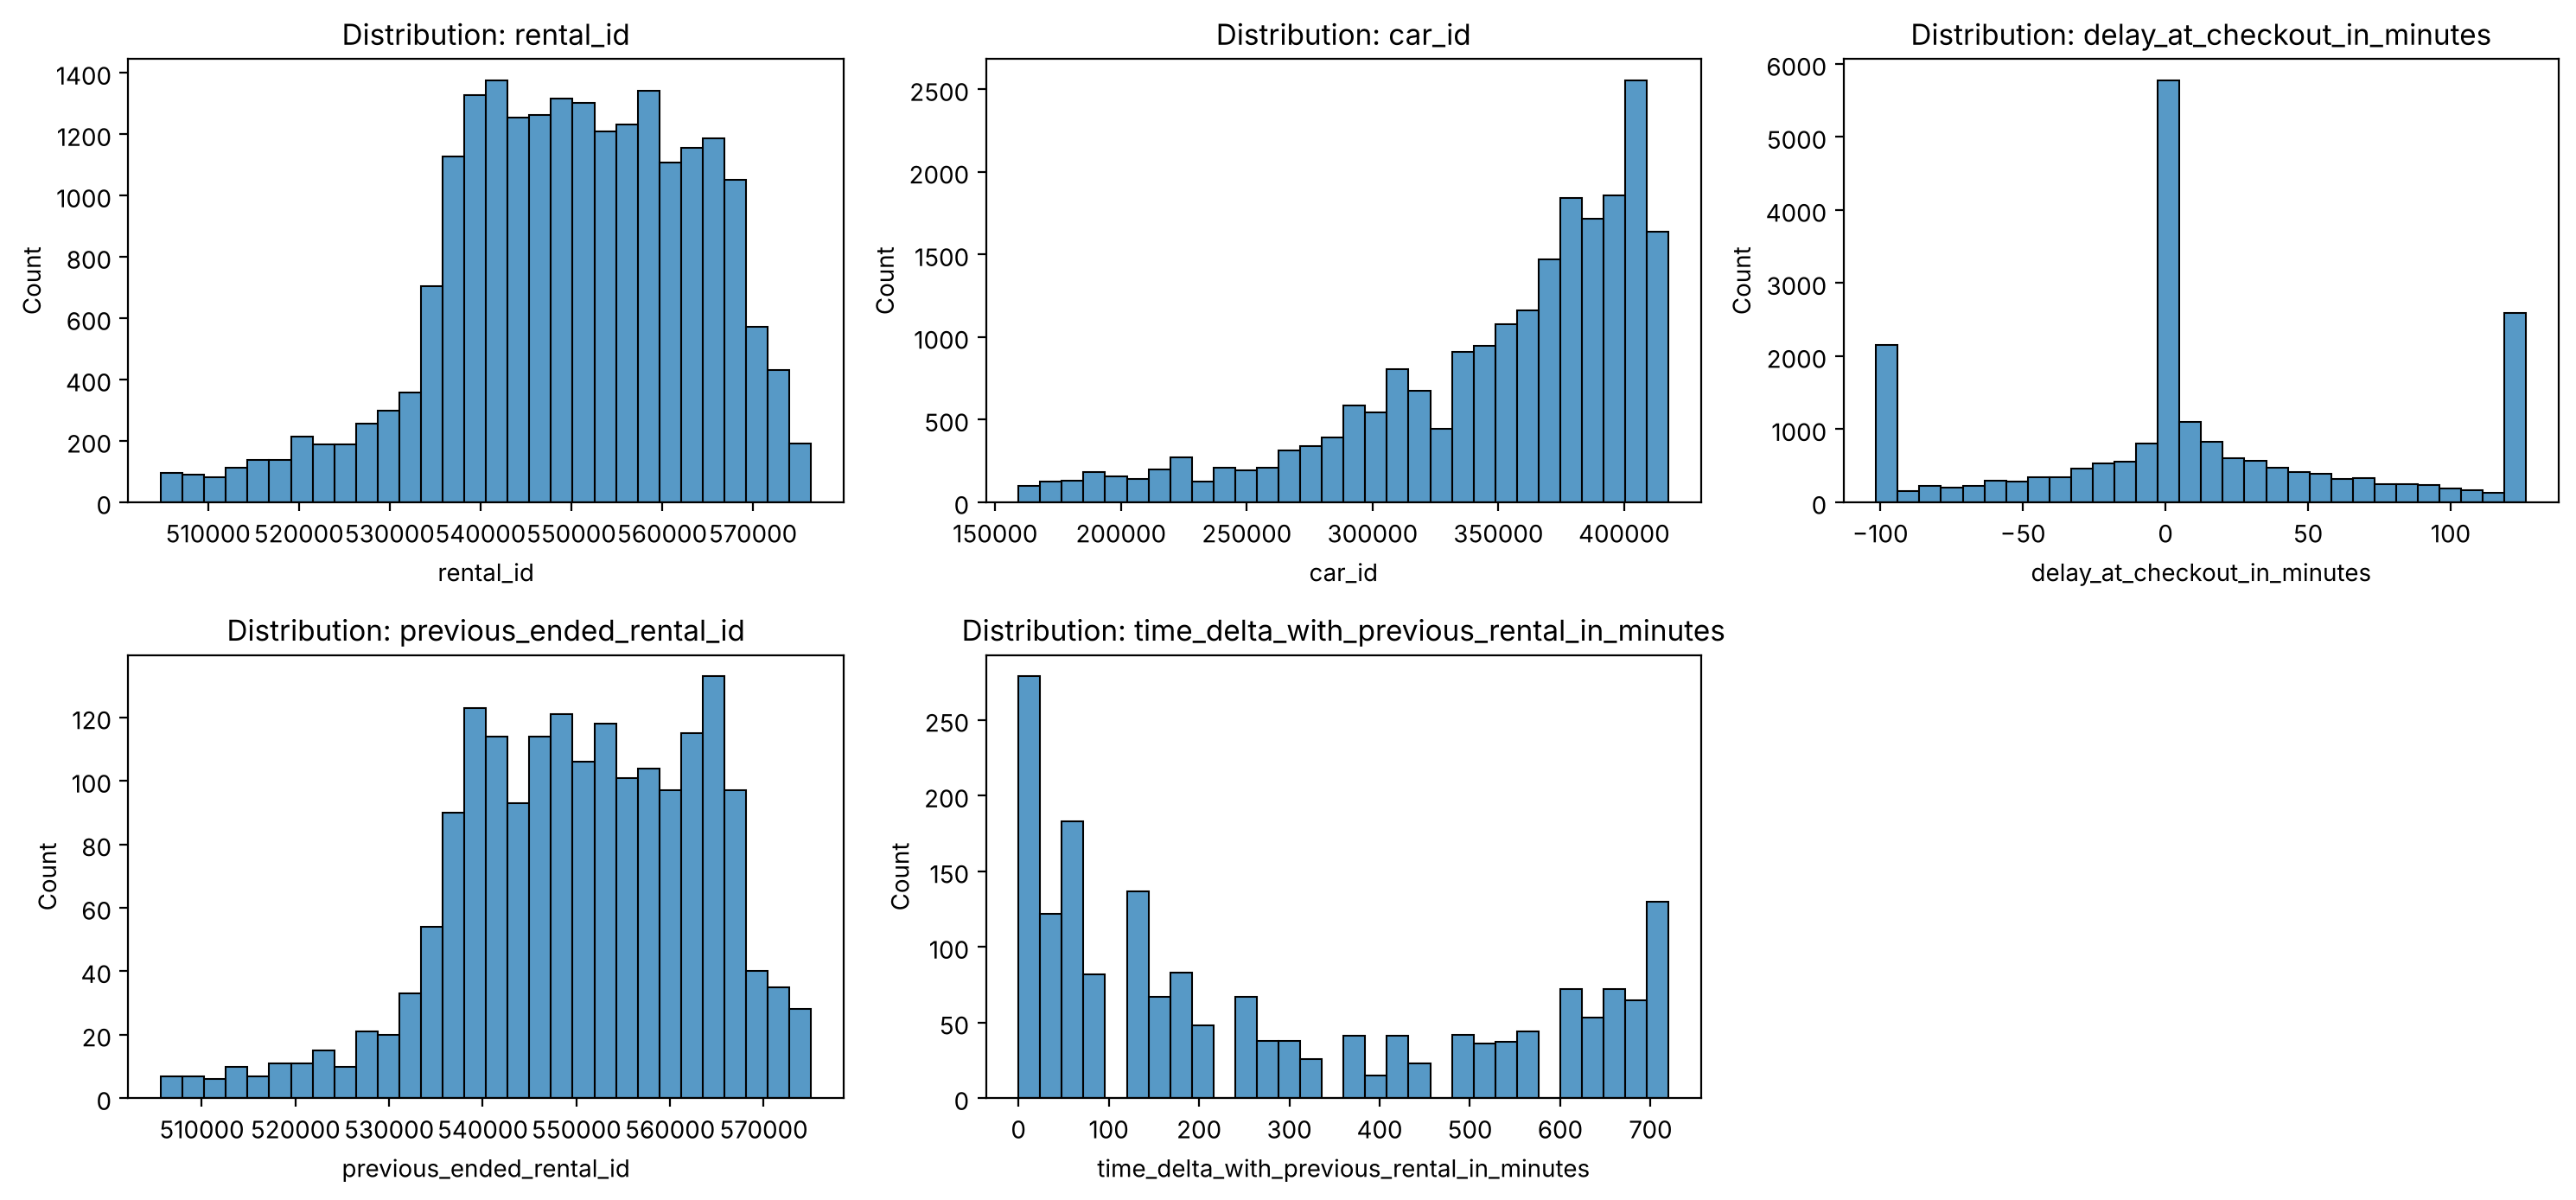

In [13]:
# Get all numerical columns in the DataFrame
numerical_columns = df.select_dtypes(include=['float64', 'int64']).columns

# Create the plot
plt.figure(figsize=(15, 10))

# Loop over numerical columns and plot their distributions
for i, column in enumerate(numerical_columns, 1):
    plt.subplot(3, 3, i)

    # Filter out -1 values from the column for visualization
    sns.histplot(df[df[column] != -1][column], kde=False, bins=30)

    # Add title for each plot
    plt.title(f'Distribution: {column}')

# Adjust the layout for better readability
plt.tight_layout()
plt.show()

In [14]:
# Count unique values for categorical columns
categorical_columns_pricing = df.select_dtypes(include=['object']).columns
for col in categorical_columns_pricing:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts())


Value counts for checkin_type:
checkin_type
mobile     17003
connect     4307
Name: count, dtype: int64

Value counts for state:
state
ended       18045
canceled     3265
Name: count, dtype: int64


## Visualisation

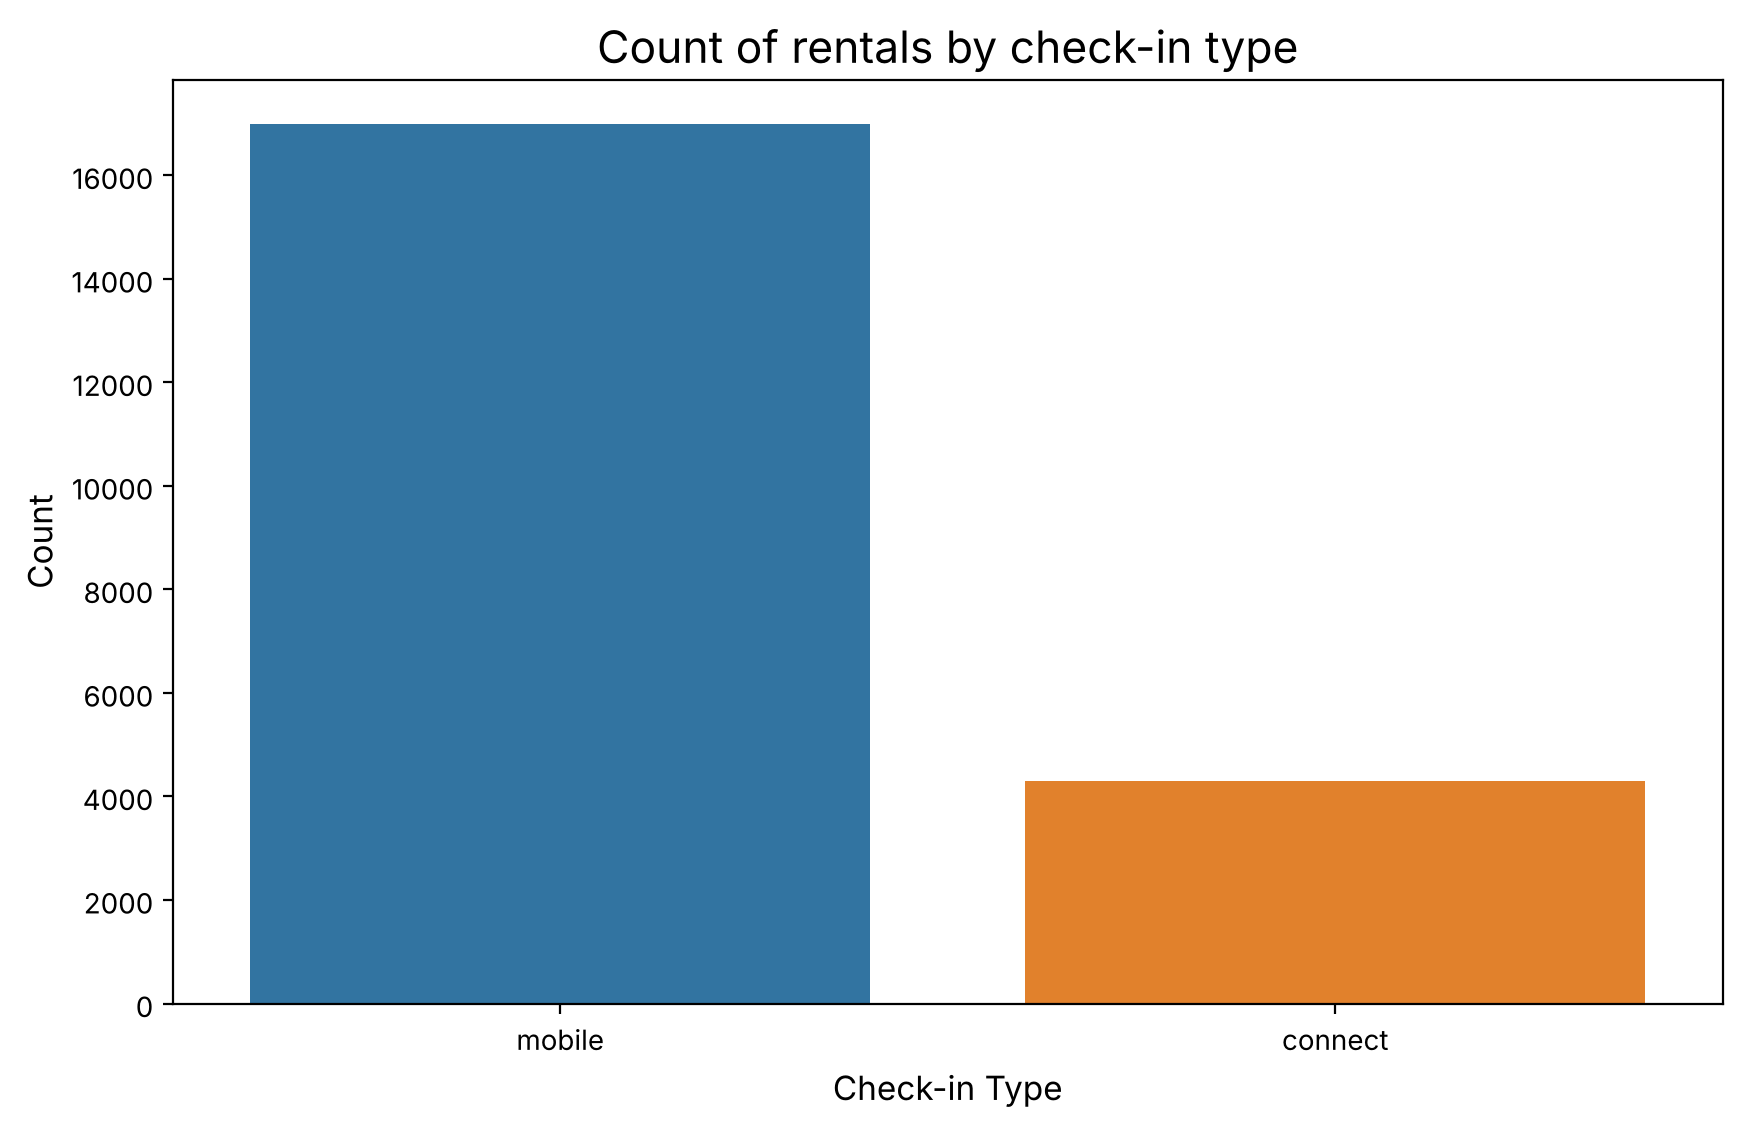

In [15]:
# Visualizing the count of rentals by check-in type and state
plt.figure(figsize=(10, 6))
sns.countplot(x='checkin_type', data=df, hue='checkin_type')
plt.title('Count of rentals by check-in type', fontsize=16)
plt.xlabel('Check-in Type', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()


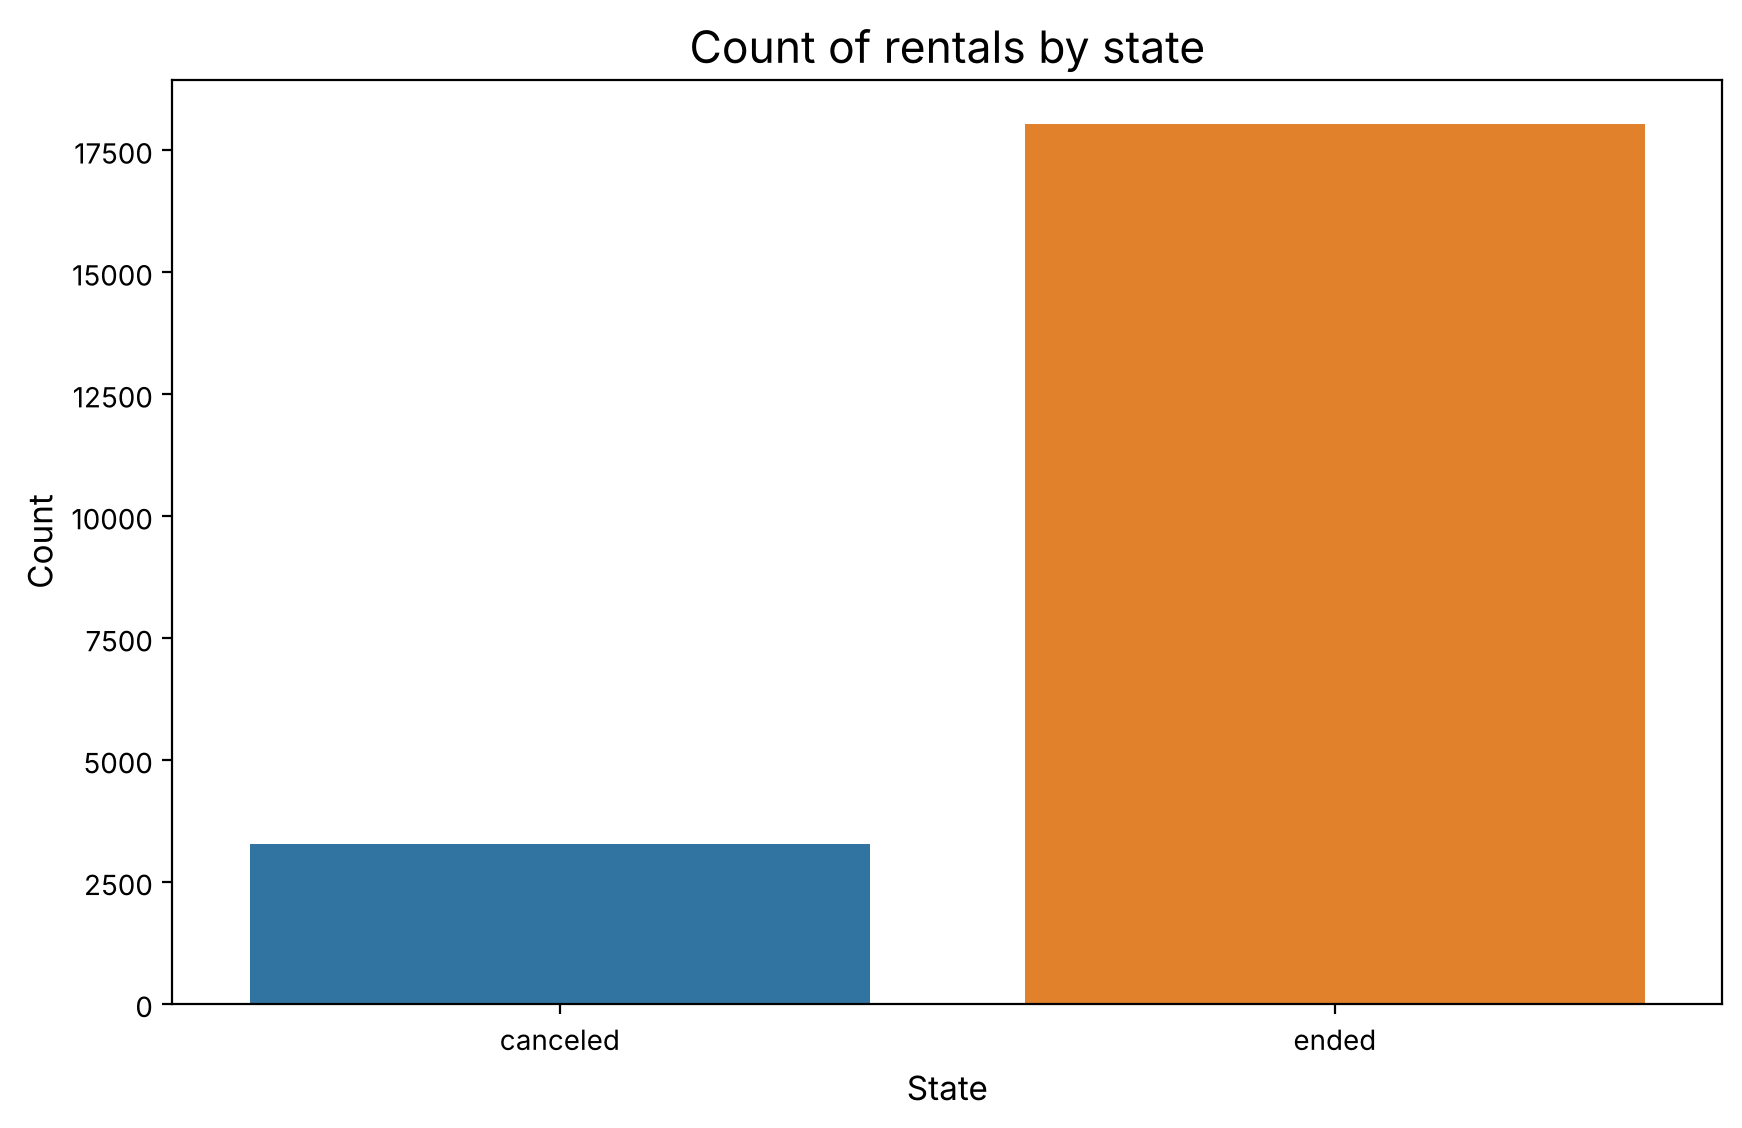

In [16]:
# Visualizing the count of rentals by state
plt.figure(figsize=(10, 6))
sns.countplot(x='state', data=df, hue='state')
plt.title('Count of rentals by state', fontsize=16)
plt.xlabel('State', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

## Export to .csv

In [17]:
# Save the cleaned dataset to a CSV file (local runs only, for EDA reuse)
if DATA_DIR.exists():
    df.to_csv(DATA_DIR / "get_around_delay_analysis.csv", index=False)

## Key takeaways

- **Late returns are common, conflicts are rare.** 58% of ended rentals with a known delay come back late (61% with mobile check-in, 43% with Connect; median delay +14 min vs. −9 min). But only 1,612 of 18,045 ended rentals start less than 12 hours after the previous rental of the same car, and 181 of them were hit by a late return.
- **60 minutes is the best trade-off.** It avoids 70% of conflicts (127 of 181) while blocking 2.0% of ended rentals. Doubling it to 120 minutes adds 15 points of conflicts avoided but blocks 65% more rentals.
- **Apply it to all cars.** Connect cars pay twice the cost (4.4% of their rentals blocked) and hold only 50 of the 181 conflicts, so a Connect-only buffer would leave most conflicts in place.
- **Cancellations strengthen the case.** 37 canceled bookings followed a late return, a higher conflict rate than for ended rentals (18% vs. 12%); the 60-minute buffer would have prevented 19 of them.
- **Limits:** the export covers a single period, cancellations have no recorded reason, and a blocked booking may be rebooked later rather than lost, so the revenue at risk is an upper bound.